##Task 1 – Data Exploration & Preprocessing
Step 1: Import libraries and load the dataset

In [1]:
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()

file_name = next(
    (name for name in uploaded if name.lower().endswith(".csv")),
    None)

if file_name is None:
    raise ValueError("Please upload your dataset in CSV format.")

df = pd.read_csv(file_name)

print("Dataset loaded successfully")
print(df.head())


Saving crowdfunding.csv to crowdfunding (6).csv
Dataset loaded successfully
   Unnamed: 0 CampaignID  GoalAmount  RaisedAmount  DurationDays  NumBackers  \
0           0  CID_00000       76159  73518.028955            15        1903   
1           1  CID_00001       69394  60068.683288            49         469   
2           2  CID_00002       18652  22958.153470            58         148   
3           3  CID_00003       19487  24229.048390            39         780   
4           4  CID_00004       26734  17984.630311            68        1622   

  Category LaunchMonth    Country Currency  OwnerExperience VideoIncluded  \
0     Film   September  Australia      GBP               11           Yes   
1      Art     October  Australia      GBP                7           Yes   
2     Film    February        USA      EUR               17            No   
3     Film     October    Germany      AUD               10            No   
4    Games   September  Australia      AUD               1

###Step 2: Explore the dataset

In [2]:
print("First five records:")
print(df.head())

print("\nLast five records:")
print(df.tail())

print("\nNumber of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nData types:")
print(df.dtypes)

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(include=["object", "category"]).columns.tolist())


First five records:
   Unnamed: 0 CampaignID  GoalAmount  RaisedAmount  DurationDays  NumBackers  \
0           0  CID_00000       76159  73518.028955            15        1903   
1           1  CID_00001       69394  60068.683288            49         469   
2           2  CID_00002       18652  22958.153470            58         148   
3           3  CID_00003       19487  24229.048390            39         780   
4           4  CID_00004       26734  17984.630311            68        1622   

  Category LaunchMonth    Country Currency  OwnerExperience VideoIncluded  \
0     Film   September  Australia      GBP               11           Yes   
1      Art     October  Australia      GBP                7           Yes   
2     Film    February        USA      EUR               17            No   
3     Film     October    Germany      AUD               10            No   
4    Games   September  Australia      AUD               12           Yes   

   SocialMediaPresence  NumUpdates  

###Step 3: Handle missing values and duplicates

In [3]:
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate records before cleaning:")
print(df.duplicated().sum())


df = df.drop_duplicates().copy()


num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    if df[col].isnull().any():
        median_value = df[col].median()
        if pd.notna(median_value):
            df[col] = df[col].fillna(median_value)


cat_cols = df.select_dtypes(include=["object", "category", "string"]).columns

for col in cat_cols:
    if df[col].isnull().any():
        common_value = df[col].mode()
        if not common_value.empty:
            df[col] = df[col].fillna(common_value.iloc[0])
        else:
            df[col] = df[col].fillna("Unknown")

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate records after cleaning:")
print(df.duplicated().sum())

print("\nCleaned dataset shape:", df.shape)


Missing values before cleaning:
Unnamed: 0             0
CampaignID             0
GoalAmount             0
RaisedAmount           0
DurationDays           0
NumBackers             0
Category               0
LaunchMonth            0
Country                0
Currency               0
OwnerExperience        0
VideoIncluded          0
SocialMediaPresence    0
NumUpdates             0
IsSuccessful           0
dtype: int64

Duplicate records before cleaning:
0

Missing values after cleaning:
Unnamed: 0             0
CampaignID             0
GoalAmount             0
RaisedAmount           0
DurationDays           0
NumBackers             0
Category               0
LaunchMonth            0
Country                0
Currency               0
OwnerExperience        0
VideoIncluded          0
SocialMediaPresence    0
NumUpdates             0
IsSuccessful           0
dtype: int64

Duplicate records after cleaning:
0

Cleaned dataset shape: (100000, 15)


##Step 4: Encode categorical variables


In [2]:
import pandas as pd
import numpy as np
from google.colab import files
from sklearn.preprocessing import LabelEncoder
uploaded = files.upload()

filename = next(
    (name for name in uploaded if name.lower().endswith(".csv")), None)

if filename is None:
    raise ValueError("Please upload a CSV file.")

df = pd.read_csv(filename)

print("Dataset loaded:", filename)
print("Original dataset shape:", df.shape)

df = df.drop_duplicates().copy()

for col in df.select_dtypes(include=np.number).columns:
    if df[col].isnull().any():
        median_value = df[col].median()
        if pd.notna(median_value):
            df[col] = df[col].fillna(median_value)

for col in df.select_dtypes(
    include=["object", "category", "string"]
).columns:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])
        else:
            df[col] = df[col].fillna("Unknown")

target_column = "IsSuccessful"

if target_column not in df.columns:
    raise ValueError(
        f"Target column not found. Available columns: {df.columns.tolist()}")

df = df.dropna(subset=[target_column]).copy()

X = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()

id_cols = [
    col for col in X.columns
    if col.lower() in ["id", "project_id", "campaign_id"]]
X = X.drop(columns=id_cols)


cat_cols = X.select_dtypes(
    include=["object", "category", "string"]).columns.tolist()

for col in cat_cols:
    X[col] = X[col].astype("category").cat.codes

if (
    pd.api.types.is_object_dtype(y)
    or isinstance(y.dtype, pd.CategoricalDtype)
    or pd.api.types.is_string_dtype(y)):
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(y.astype(str))


print("\nCategorical encoding completed.")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nEncoded features:")
print(X.head())

print("\nTarget values:")
print(pd.Series(y).value_counts())


Saving crowdfunding.csv to crowdfunding (7).csv
Dataset loaded: crowdfunding (7).csv
Original dataset shape: (100000, 15)

Categorical encoding completed.
Feature shape: (100000, 14)
Target shape: (100000,)

Encoded features:
   Unnamed: 0  CampaignID  GoalAmount  RaisedAmount  DurationDays  NumBackers  \
0           0           0       76159  73518.028955            15        1903   
1           1           1       69394  60068.683288            49         469   
2           2           2       18652  22958.153470            58         148   
3           3           3       19487  24229.048390            39         780   
4           4           4       26734  17984.630311            68        1622   

   Category  LaunchMonth  Country  Currency  OwnerExperience  VideoIncluded  \
0         1           11        0         3               11              1   
1         0           10        0         3                7              1   
2         1            3        4         2       

###5. Split the dataset into training and testing sets

In [3]:
from sklearn.model_selection import train_test_split
import pandas as pd

if "X" not in globals() or "y" not in globals():
    raise ValueError("X and y are not available. Run Step 4 first.")

class_counts = pd.Series(y).value_counts()

if len(class_counts) > 1 and class_counts.min() >= 2:
    stratify_option = y
else:
    stratify_option = None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_option)

print("Dataset split completed successfully!")

print("\nOriginal feature shape:", X.shape)
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining data percentage: 80%")
print("Testing data percentage: 20%")


Dataset split completed successfully!

Original feature shape: (100000, 14)
Training feature shape: (80000, 14)
Testing feature shape: (20000, 14)

Training target shape: (80000,)
Testing target shape: (20000,)

Training data percentage: 80%
Testing data percentage: 20%


###6. Apply feature scaling where required

In [5]:
from sklearn.preprocessing import StandardScaler
numeric_columns = X_train.select_dtypes(
    include=["int64", "float64"]).columns.tolist()

if "cat_cols" in globals():
    numeric_columns = [
        col for col in numeric_columns
        if col not in cat_cols]

X_train = X_train.copy()
X_test = X_test.copy()

scaler = StandardScaler()

if numeric_columns:
    X_train[numeric_columns] = X_train[numeric_columns].astype(float)
    X_test[numeric_columns] = X_test[numeric_columns].astype(float)
    X_train[numeric_columns] = scaler.fit_transform(
        X_train[numeric_columns])

    X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

    print("Feature scaling completed successfully!")
    print("\nScaled training data:")
    print(X_train.head())

    print("\nTraining data shape:", X_train.shape)
    print("Testing data shape:", X_test.shape)

    print("\nMean of scaled training features:")
    print(X_train[numeric_columns].mean().round(2))
else:
    print("No numerical columns found for scaling.")


Feature scaling completed successfully!

Scaled training data:
       Unnamed: 0  CampaignID  GoalAmount  RaisedAmount  DurationDays  \
5447    -1.543373        5447    0.079275     -0.632259     -1.156610   
58339    0.287467       58339    1.203468     -0.091784     -0.786992   
67240    0.595573       67240   -0.549472     -0.640222     -0.463576   
55586    0.192173       55586    1.247680      1.551733      1.292110   
26366   -0.819268       26366    0.134906     -0.632147     -0.879396   

       NumBackers  Category  LaunchMonth  Country  Currency  OwnerExperience  \
5447    -1.514726         4           11        4         2         1.131265   
58339    1.122742         0           10        0         4         1.478455   
67240    0.051053         2            7        1         4        -1.299066   
55586    1.192333         2            4        2         3        -0.257496   
26366    1.070550         3            5        3         0        -0.951876   

       VideoInclu

###Task 2 – Classification Model Building
Build and train the following classification models:
● Random Forest Classifier
● KNN
● Decision Tree
● Naive Bayes Classifier
● Support Vector Machine (SVM)
Experiment with different model parameters to improve performance.

In [6]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Check whether Task 1 data is available
if not all(name in globals() for name in
           ["X_train", "X_test", "y_train", "y_test"]):
    raise ValueError("Please complete Task 1 first.")

# Create the classification models
models = {"Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=15, random_state=42),
    "Naive Bayes": GaussianNB(var_smoothing=1e-9),
    "SVM": LinearSVC(C=1.0, max_iter=3000, random_state=42)}
results = []

for name, model in models.items():
    print("\nTraining", name, "...")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, average="weighted", zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, average="weighted", zero_division=0), 4),
        "F1 Score": round(f1_score(y_test, y_pred, average="weighted", zero_division=0), 4)})

results_df = pd.DataFrame(results)
print("\nClassification Model Performance:")
print(results_df.to_string(index=False))



Training Random Forest ...

Training KNN ...

Training Decision Tree ...

Training Naive Bayes ...

Training SVM ...

Classification Model Performance:
        Model  Accuracy  Precision  Recall  F1 Score
Random Forest    0.8920     0.9082  0.8920    0.8909
          KNN    0.5100     0.5100  0.5100    0.5100
Decision Tree    0.9771     0.9774  0.9771    0.9771
  Naive Bayes    0.6726     0.6972  0.6726    0.6623
          SVM    0.9989     0.9989  0.9989    0.9989


In [7]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
import pandas as pd

experiments = [
    ("Random Forest - 100 trees",
     RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)),
    ("Random Forest - 150 trees", RandomForestClassifier(n_estimators=150, max_depth=20, random_state=42, n_jobs=-1)),
    ("KNN - 3 neighbors", KNeighborsClassifier(n_neighbors=3)),
    ("KNN - 7 neighbors", KNeighborsClassifier(n_neighbors=7)),
    ("Decision Tree - depth 10", DecisionTreeClassifier(max_depth=10, random_state=42)),
    ("Decision Tree - depth 20", DecisionTreeClassifier(max_depth=20, random_state=42)),
    ("Naive Bayes - smoothing 1e-9", GaussianNB(var_smoothing=1e-9)),
    ("Naive Bayes - smoothing 1e-8", GaussianNB(var_smoothing=1e-8)),
    ("SVM - C 0.1", LinearSVC(C=0.1, max_iter=3000, random_state=42)),
    ("SVM - C 1.0", LinearSVC(C=1.0, max_iter=3000, random_state=42))]

experiment_results = []

for name, model in experiments:
    print("Testing:", name)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    experiment_results.append({"Experiment": name, "Accuracy": round(accuracy_score(y_test, predictions), 4)})

experiment_df = pd.DataFrame(experiment_results)
experiment_df = experiment_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

print("\nParameter Experiment Results:")
print(experiment_df.to_string(index=False))


Testing: Random Forest - 100 trees
Testing: Random Forest - 150 trees
Testing: KNN - 3 neighbors
Testing: KNN - 7 neighbors
Testing: Decision Tree - depth 10
Testing: Decision Tree - depth 20
Testing: Naive Bayes - smoothing 1e-9
Testing: Naive Bayes - smoothing 1e-8
Testing: SVM - C 0.1
Testing: SVM - C 1.0

Parameter Experiment Results:
                  Experiment  Accuracy
                 SVM - C 1.0    0.9989
                 SVM - C 0.1    0.9987
    Decision Tree - depth 20    0.9901
   Random Forest - 150 trees    0.9375
    Decision Tree - depth 10    0.9274
   Random Forest - 100 trees    0.8920
Naive Bayes - smoothing 1e-9    0.6726
Naive Bayes - smoothing 1e-8    0.6724
           KNN - 3 neighbors    0.5112
           KNN - 7 neighbors    0.5102


###Task 3 – Model Evaluation
Evaluate all models using:
● Accuracy
● Precision
● Recall
● F1-Score
● Confusion Matrix
Compare training and testing performance

In [8]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

evaluation_results = []

for name, model in models.items():

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)
    train_accuracy = accuracy_score(y_train, train_predictions)

    test_accuracy = accuracy_score(y_test, test_predictions)
    precision = precision_score(y_test, test_predictions,average="weighted", zero_division=0)
    recall = recall_score(y_test, test_predictions,average="weighted", zero_division=0)
    f1 = f1_score(y_test, test_predictions,average="weighted", zero_division=0)

    evaluation_results.append({
        "Model": name,
        "Training Accuracy": round(train_accuracy, 4),
        "Testing Accuracy": round(test_accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-Score": round(f1, 4),
        "Accuracy Gap": round(train_accuracy - test_accuracy, 4)})

evaluation_df = pd.DataFrame(evaluation_results)
print("MODEL EVALUATION RESULTS")
print(evaluation_df.to_string(index=False))


MODEL EVALUATION RESULTS
        Model  Training Accuracy  Testing Accuracy  Precision  Recall  F1-Score  Accuracy Gap
Random Forest             0.9338            0.8920     0.9082  0.8920    0.8909        0.0419
          KNN             0.6933            0.5100     0.5100  0.5100    0.5100        0.1833
Decision Tree             0.9829            0.9771     0.9774  0.9771    0.9771        0.0058
  Naive Bayes             0.6672            0.6726     0.6972  0.6726    0.6623       -0.0055
          SVM             0.9990            0.9989     0.9989  0.9989    0.9989        0.0001


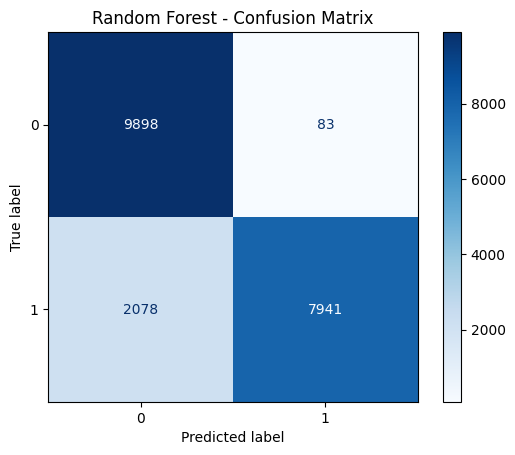

Random Forest
[[9898   83]
 [2078 7941]]
----------------------------------------


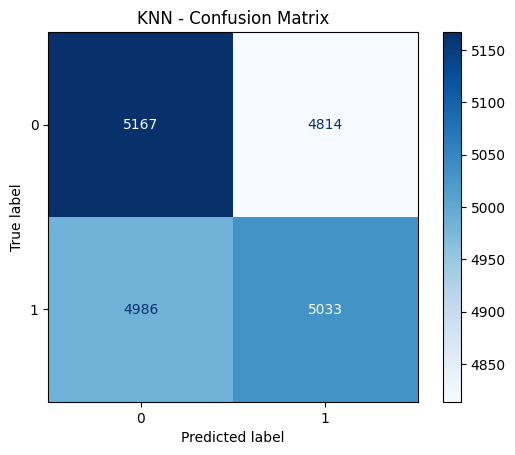

KNN
[[5167 4814]
 [4986 5033]]
----------------------------------------


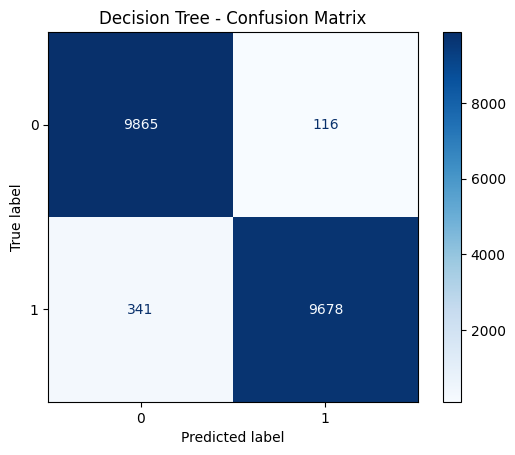

Decision Tree
[[9865  116]
 [ 341 9678]]
----------------------------------------


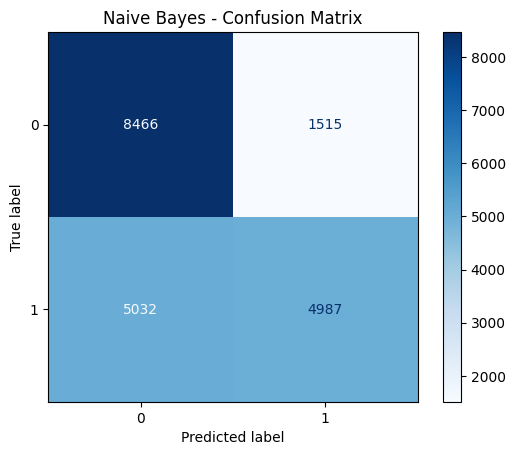

Naive Bayes
[[8466 1515]
 [5032 4987]]
----------------------------------------


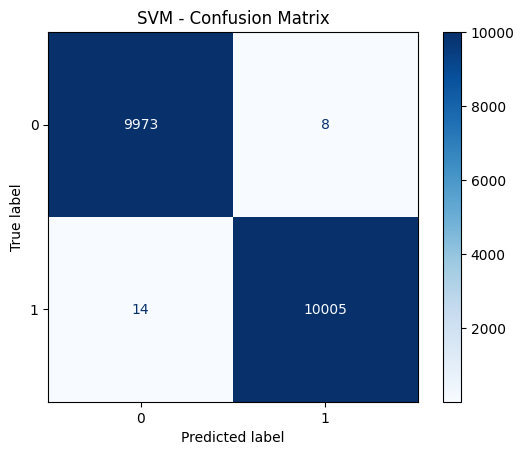

SVM
[[ 9973     8]
 [   14 10005]]
----------------------------------------


In [9]:

for name, model in models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(y_test, predictions)

    display = ConfusionMatrixDisplay(confusion_matrix=cm)

    display.plot(cmap="Blues", values_format="d")
    plt.title(name + " - Confusion Matrix")
    plt.show()

    print(name)
    print(cm)
    print("-" * 40)


Logistic Regression: The confusion matrix shows how accurately the Logistic Regression model classifies successful and unsuccessful crowdfunding projects.
Decision Tree: The confusion matrix illustrates the Decision Tree model’s correct and incorrect predictions for successful and unsuccessful projects.
Random Forest: The confusion matrix displays the Random Forest model’s classification performance by comparing actual and predicted outcomes.
Support Vector Machine (SVM): The confusion matrix shows how well the SVM model distinguishes between successful and unsuccessful crowdfunding projects.
K-Nearest Neighbors (KNN): The confusion matrix represents the KNN model’s correct classifications and misclassifications of crowdfunding projects.
Naive Bayes: The confusion matrix evaluates the Naive Bayes model by comparing the actual project outcomes with its predictions.

In [10]:
for name, model in models.items():
    predictions = model.predict(X_test)
    print("\nClassification Report:", name)
    print(classification_report(
        y_test,
        predictions,
        zero_division=0))



Classification Report: Random Forest
              precision    recall  f1-score   support

           0       0.83      0.99      0.90      9981
           1       0.99      0.79      0.88     10019

    accuracy                           0.89     20000
   macro avg       0.91      0.89      0.89     20000
weighted avg       0.91      0.89      0.89     20000


Classification Report: KNN
              precision    recall  f1-score   support

           0       0.51      0.52      0.51      9981
           1       0.51      0.50      0.51     10019

    accuracy                           0.51     20000
   macro avg       0.51      0.51      0.51     20000
weighted avg       0.51      0.51      0.51     20000


Classification Report: Decision Tree
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      9981
           1       0.99      0.97      0.98     10019

    accuracy                           0.98     20000
   macro avg       0.98 

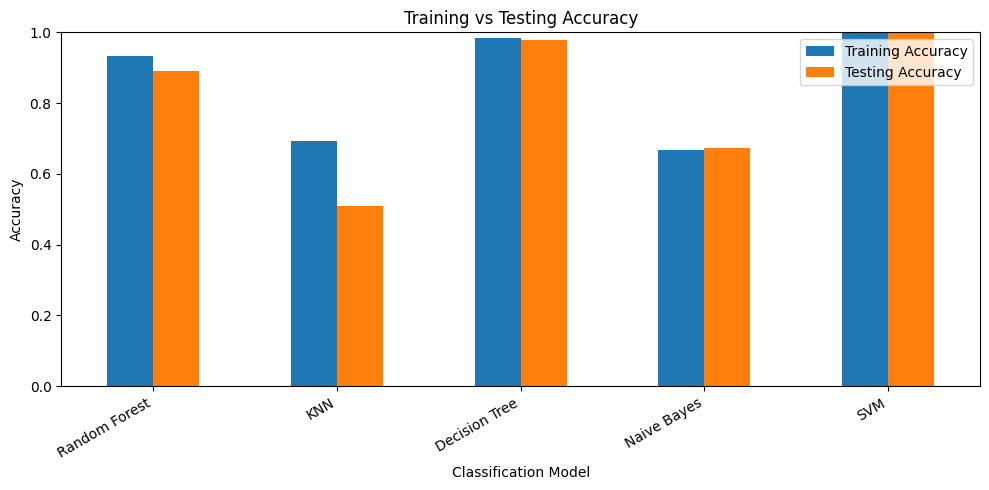

In [11]:

evaluation_df.plot(
    x="Model",
    y=["Training Accuracy", "Testing Accuracy"],
    kind="bar",
    figsize=(10, 5))

plt.title("Training vs Testing Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Classification Model")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


The bar chart compares the training and testing accuracy of all classification models to evaluate their performance and identify potential overfitting or underfitting.

In [12]:
best_model_row = evaluation_df.sort_values(
    by="F1-Score", ascending=False).iloc[0]

print("Best model based on testing F1-Score:",
      best_model_row["Model"])

print("Testing Accuracy:",
      best_model_row["Testing Accuracy"])

print("Precision:", best_model_row["Precision"])
print("Recall:", best_model_row["Recall"])
print("F1-Score:", best_model_row["F1-Score"])

print("Training Accuracy:",
      best_model_row["Training Accuracy"])

print("Accuracy Gap:",
      best_model_row["Accuracy Gap"])


Best model based on testing F1-Score: SVM
Testing Accuracy: 0.9989
Precision: 0.9989
Recall: 0.9989
F1-Score: 0.9989
Training Accuracy: 0.999
Accuracy Gap: 0.0001


###Task 4 – Cross-Validation & Hyperparameter Tuning
● Apply Cross-Validation to evaluate model stability
● Perform Hyperparameter Tuning using GridSearchCV or RandomizedSearchCV
● Identify the best parameters for each model

In [13]:
import pandas as pd
import numpy as np

from sklearn.model_selection import (train_test_split,RandomizedSearchCV)
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

if not all(name in globals() for name in ["X_train", "X_test", "y_train", "y_test"]): raise ValueError("Please complete Task 1 first.")

X_tune, _, y_tune, _ = train_test_split(X_train, y_train,train_size=min(20000, len(X_train)),random_state=42, stratify=y_train)

print("Data prepared for hyperparameter tuning.")
print("Tuning sample shape:", X_tune.shape)


Data prepared for hyperparameter tuning.
Tuning sample shape: (20000, 14)


In [14]:
models_for_tuning = {
    "Random Forest": {"model": RandomForestClassifier(random_state=42, n_jobs=1),
        "params": {
            "n_estimators": [100, 150],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5]}},

    "KNN": {
        "model": KNeighborsClassifier(n_jobs=1),
        "params": {"n_neighbors": [3, 5, 7], "weights": ["uniform", "distance"]}},

    "Decision Tree": {"model": DecisionTreeClassifier(random_state=42),
        "params": {
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5, 10],
            "criterion": ["gini", "entropy"]}},

    "Naive Bayes": {"model": GaussianNB(),
        "params": {"var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]}},

    "SVM": {
        "model": LinearSVC(
            max_iter=5000, random_state=42),
        "params": {
            "C": [0.1, 1.0, 10.0]}}}

print("Five classification models are ready for tuning.")


Five classification models are ready for tuning.


In [15]:
tuning_results = []
best_models = {}

for name, details in models_for_tuning.items():

    print("\nTuning:", name)

    search = RandomizedSearchCV(
        estimator=details["model"],
        param_distributions=details["params"],
        n_iter=min(4, np.prod([len(values) for values in details["params"].values()]).astype(int)),
        scoring="f1_weighted", cv=3, random_state=42, n_jobs=-1, refit=True, return_train_score=False)

    search.fit(X_tune, y_tune)

    best_models[name] = search.best_estimator_

    best_index = search.best_index_

    tuning_results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "Best CV F1-Score": round(search.best_score_, 4),
        "CV Standard Deviation": round(
            search.cv_results_["std_test_score"][best_index], 4)})

    print("Best parameters:", search.best_params_)
    print("Best CV F1-Score:", round(search.best_score_, 4))
    print("CV standard deviation:", round(
        search.cv_results_["std_test_score"][best_index], 4))

tuning_df = pd.DataFrame(tuning_results)

print("\nHYPERPARAMETER TUNING RESULTS")
print(tuning_df.to_string(index=False))



Tuning: Random Forest
Best parameters: {'n_estimators': 150, 'min_samples_split': 2, 'max_depth': None}
Best CV F1-Score: 0.9295
CV standard deviation: 0.0079

Tuning: KNN
Best parameters: {'weights': 'distance', 'n_neighbors': 7}
Best CV F1-Score: 0.5074
CV standard deviation: 0.0033

Tuning: Decision Tree
Best parameters: {'min_samples_split': 10, 'max_depth': None, 'criterion': 'gini'}
Best CV F1-Score: 0.9802
CV standard deviation: 0.0006

Tuning: Naive Bayes
Best parameters: {'var_smoothing': 1e-09}
Best CV F1-Score: 0.6571
CV standard deviation: 0.0073

Tuning: SVM
Best parameters: {'C': 1.0}
Best CV F1-Score: 0.9942
CV standard deviation: 0.0007

HYPERPARAMETER TUNING RESULTS
        Model                                                   Best Parameters  Best CV F1-Score  CV Standard Deviation
Random Forest  {'n_estimators': 150, 'min_samples_split': 2, 'max_depth': None}            0.9295                 0.0079
          KNN                         {'weights': 'distance', 'n_

In [16]:
for name, model in best_models.items():
    print("Training best model on full training data:", name)
    model.fit(X_train, y_train)

print("\nAll tuned models have been trained on the full training dataset.")


Training best model on full training data: Random Forest
Training best model on full training data: KNN
Training best model on full training data: Decision Tree
Training best model on full training data: Naive Bayes
Training best model on full training data: SVM

All tuned models have been trained on the full training dataset.


In [17]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)
final_results = []
for name, model in best_models.items():
    predictions = model.predict(X_test)
    final_results.append({
        "Model": name,
        "Test Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Test Precision": round(precision_score(y_test, predictions,average="weighted", zero_division=0), 4),
        "Test Recall": round(recall_score(y_test, predictions, average="weighted", zero_division=0), 4),
        "Test F1-Score": round(f1_score(y_test, predictions,average="weighted", zero_division=0), 4)})

final_tuning_df = pd.DataFrame(final_results)
print("PERFORMANCE OF TUNED MODELS")
print(final_tuning_df.to_string(index=False))


PERFORMANCE OF TUNED MODELS
        Model  Test Accuracy  Test Precision  Test Recall  Test F1-Score
Random Forest         0.9635          0.9645       0.9635         0.9634
          KNN         0.5114          0.5114       0.5114         0.5114
Decision Tree         0.9925          0.9925       0.9925         0.9925
  Naive Bayes         0.6726          0.6972       0.6726         0.6623
          SVM         0.9989          0.9989       0.9989         0.9989


###

Task 5 Model Comparison & Selection
● Compare all classification models using evaluation metrics
● Identify the best-performing model
● Discuss strengths, weaknesses, and possible improvements

In [18]:
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score,recall_score, f1_score)
comparison_results = []
for name in models.keys():

    if "best_models" in globals() and name in best_models:
        model = best_models[name]
    else:
        model = models[name]

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    comparison_results.append({
        "Model": name,
        "Training Accuracy": round(
            accuracy_score(y_train, train_pred), 4),
        "Testing Accuracy": round(
            accuracy_score(y_test, test_pred), 4),
        "Precision": round(
            precision_score(
                y_test, test_pred,
                average="weighted", zero_division=0), 4),
        "Recall": round(
            recall_score(
                y_test, test_pred,
                average="weighted", zero_division=0), 4),
        "F1-Score": round(
            f1_score(
                y_test, test_pred,
                average="weighted", zero_division=0), 4)})

comparison_df = pd.DataFrame(comparison_results)
print("CLASSIFICATION MODEL COMPARISON")
print(comparison_df.to_string(index=False))


CLASSIFICATION MODEL COMPARISON
        Model  Training Accuracy  Testing Accuracy  Precision  Recall  F1-Score
Random Forest             1.0000            0.9635     0.9645  0.9635    0.9634
          KNN             1.0000            0.5114     0.5114  0.5114    0.5114
Decision Tree             0.9987            0.9925     0.9925  0.9925    0.9925
  Naive Bayes             0.6672            0.6726     0.6972  0.6726    0.6623
          SVM             0.9990            0.9989     0.9989  0.9989    0.9989


In [19]:
best_row = comparison_df.loc[
    comparison_df["F1-Score"].idxmax()]

print("BEST-PERFORMING MODEL")
print("---------------------")
print("Model:", best_row["Model"])
print("Training Accuracy:", best_row["Training Accuracy"])
print("Testing Accuracy:", best_row["Testing Accuracy"])
print("Precision:", best_row["Precision"])
print("Recall:", best_row["Recall"])
print("F1-Score:", best_row["F1-Score"])
accuracy_gap = (
    best_row["Training Accuracy"] -
    best_row["Testing Accuracy"])
print("Training-Testing Accuracy Gap:", round(accuracy_gap, 4))


BEST-PERFORMING MODEL
---------------------
Model: SVM
Training Accuracy: 0.999
Testing Accuracy: 0.9989
Precision: 0.9989
Recall: 0.9989
F1-Score: 0.9989
Training-Testing Accuracy Gap: 0.0001


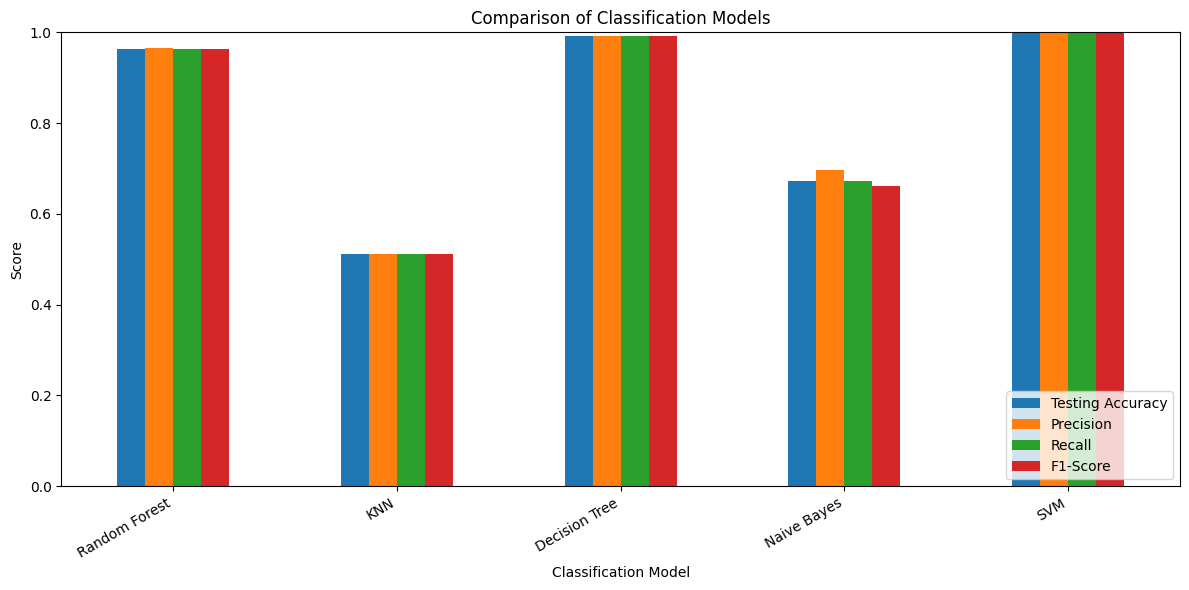

In [20]:
import matplotlib.pyplot as plt
comparison_df.plot(
    x="Model",
    y=["Testing Accuracy", "Precision", "Recall", "F1-Score"],
    kind="bar",
    figsize=(12, 6))
plt.title("Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


The bar chart compares the training and testing accuracy of all classification models to evaluate their performance and identify potential overfitting or underfitting.